## MLPI Textbook — Chapter 1 companion notebook

# Machine Learning Next to Control and Estimation

---

A packaging plant runs its conveyors on small induction-motor drives. Every drive end bearing carries
an accelerometer, and an edge device records a 0.2 s window of vibration a few times per shift. The
maintenance team wants an alarm that says **healthy** or **outer-race defect** for each window.

This notebook builds that alarm three ways: with a hand-written engineering rule, with an artificial
neuron written from scratch in NumPy (perceptron and Adaline), and with scikit-learn's `fit` /
`predict` pattern. It ends with the chapter's **decisive experiment**: is the model detecting the
fault, or is it detecting how hard the conveyor was working?

Every figure and number in Chapter 1 is produced here. The data are simulated inside the notebook
with fixed seeds, so it runs offline in under a minute.

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn
from scipy.stats import kurtosis

print("python      ", sys.version.split()[0])
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scipy       ", scipy.__version__)
print("matplotlib  ", matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
try:
    import torch
    print("torch       ", torch.__version__, "(needed from Chapter 8 on)")
except ImportError:
    print("torch        not installed (not needed until Chapter 8)")

# plot style shared by every chapter of the book
plt.rcParams.update({
    "figure.figsize": (9, 3.6), "figure.dpi": 110,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "font.size": 10, "legend.frameon": False,
})
BLUE, ORANGE, AQUA, YELLOW, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#898781"
CLASS_COLORS = [BLUE, ORANGE]          # healthy, faulty
CLASS_NAMES = ["healthy", "outer-race defect"]

os.makedirs("figures", exist_ok=True)


def savefig(name):
    """Save the current figure for the chapter text (figures/<name>.png)."""
    plt.savefig(f"figures/{name}.png", dpi=160, bbox_inches="tight")

python       3.13.18
numpy        2.5.3
pandas       3.0.5
scipy        1.18.1
matplotlib   3.11.2
scikit-learn 1.9.1
torch        not installed (not needed until Chapter 8)


---
## 1. The signals

### 1.1 A bearing simulator

The simulator uses standard vibration physics, in the same form as Chapter 2:

* the shaft turns at $f$ = 20–30 Hz and produces vibration at $1\times f$ and a little at $2\times f$;
* broadband noise from the gearbox and belt sits underneath;
* an **outer-race defect** produces an impact every time a rolling element passes it, at the
  ball-pass frequency $\text{BPFO}\approx 3.58\,f$; each impact rings the housing resonance
  (1.5–2 kHz), which decays in about a millisecond;
* the **load** on the conveyor scales everything: a heavier load means more vibration at every
  frequency and harder impacts;
* each accelerometer has its own mounting gain and a small DC offset.

The sample rate is $f_s$ = 5 kHz and one window is 1000 samples (0.2 s, four to six shaft turns).

In [2]:
FS = 5000      # Hz
WIN = 1000     # samples per window (0.2 s)


def simulate_windows(f, load, gain, faulty, severity, n_windows, rng, offset=0.0):
    """Return an (n_windows, WIN) array of accelerometer windows (g) from one drive."""
    T = n_windows * WIN
    t = np.arange(T) / FS
    ph = rng.uniform(0, 2 * np.pi, 2)
    s = load * gain
    x = s * (0.30 * np.sin(2 * np.pi * f * t + ph[0]) + 0.08 * np.sin(2 * np.pi * 2 * f * t + ph[1]))
    x += s * 0.10 * rng.standard_normal(T)                   # gearbox / belt noise
    if faulty:
        period = 1.0 / (3.58 * f)                           # BPFO
        hits = np.arange(rng.uniform(0, period), T / FS, period)
        hits += rng.normal(0, 0.01 * period, hits.size)      # rolling elements slip a little
        idx = (hits * FS).astype(int)
        idx = idx[(idx >= 0) & (idx < T)]
        f_res, tau = rng.uniform(1500, 2000), 0.0012          # housing resonance, decay time
        tk = np.arange(int(0.008 * FS)) / FS
        ring = np.exp(-tk / tau) * np.sin(2 * np.pi * f_res * tk)
        impulses = np.zeros(T)
        impulses[idx] = severity * s * rng.uniform(0.7, 1.3, idx.size)
        x += np.convolve(impulses, ring)[:T]
    x += offset
    return x.reshape(n_windows, WIN)

### 1.2 Six numbers per window

A window is 1000 numbers. We reduce it to six **features**. The first four are the ones from the
Week 1 lab; the last two are dimensionless *shape* measures from condition monitoring.

| feature | definition | depends on load? |
|---|---|---|
| `mean` | $\bar x$ | no (sensor offset) |
| `std` | $\sqrt{\tfrac1N\sum (x_i-\bar x)^2}$ | yes |
| `rms` | $\sqrt{\tfrac1N\sum x_i^2}$ | yes |
| `ptp` | $\max x - \min x$ | yes |
| `kurtosis` | $\tfrac1N\sum (x_i-\bar x)^4 / \sigma^4$ | no |
| `crest` | $\max\lvert x-\bar x\rvert / \sigma$ | no |

In [3]:
FEATURES = ["mean", "std", "rms", "ptp", "kurtosis", "crest"]
SIZE = ["rms", "ptp"]                # grow with load
SHAPE = ["kurtosis", "crest"]        # dimensionless
LAB4 = ["mean", "std", "rms", "ptp"] # the Week 1 lab's features


def window_features(W):
    centred = W - W.mean(axis=1, keepdims=True)
    sd = W.std(axis=1)
    return pd.DataFrame({
        "mean": W.mean(axis=1),
        "std": sd,
        "rms": np.sqrt((W ** 2).mean(axis=1)),
        "ptp": np.ptp(W, axis=1),
        "kurtosis": kurtosis(W, axis=1, fisher=False),
        "crest": np.abs(centred).max(axis=1) / sd,
    })


def campaign(n_drives, load_healthy, load_faulty, seed, first_id, n_windows=30):
    """Log n_drives drives (alternating healthy / faulty), n_windows windows each."""
    rng = np.random.default_rng(seed)
    parts, raw = [], {}
    for k in range(n_drives):
        faulty = k % 2
        f = rng.uniform(20, 30)
        gain = rng.uniform(0.8, 1.25)
        load = rng.uniform(*(load_faulty if faulty else load_healthy))
        sev = rng.uniform(0.6, 1.0)
        W = simulate_windows(f, load, gain, faulty, sev, n_windows, rng, rng.normal(0, 0.02))
        d = window_features(W)
        d["label"] = faulty
        d["drive"] = first_id + k
        d["load"] = load
        d["shaft_hz"] = f
        parts.append(d)
        raw[first_id + k] = W
    return pd.concat(parts, ignore_index=True), raw

### 1.3 The maintenance log

The plant's log covers **20 drives**, half of them with a confirmed outer-race defect, 30 windows
each. One detail matters later: the defects were found on the packaging line's two heavy-duty
conveyors, where bearings wear out first. So in this log the faulty drives also happen to run at a
higher load (1.0–1.4 of rated) than the healthy ones (0.7–1.1). Nobody designed it that way. It is
simply where the faults were.

In [4]:
log, log_raw = campaign(20, load_healthy=(0.7, 1.1), load_faulty=(1.0, 1.4), seed=1, first_id=0)
print(log.shape)
print(log.groupby("label")[FEATURES + ["load"]].mean().round(3).rename(index=dict(enumerate(CLASS_NAMES))))

(600, 10)
                    mean    std    rms    ptp  kurtosis  crest   load
label                                                                
healthy            0.008  0.241  0.241  1.159     2.101  2.557  0.946
outer-race defect -0.005  0.353  0.354  2.510     3.084  3.892  1.260


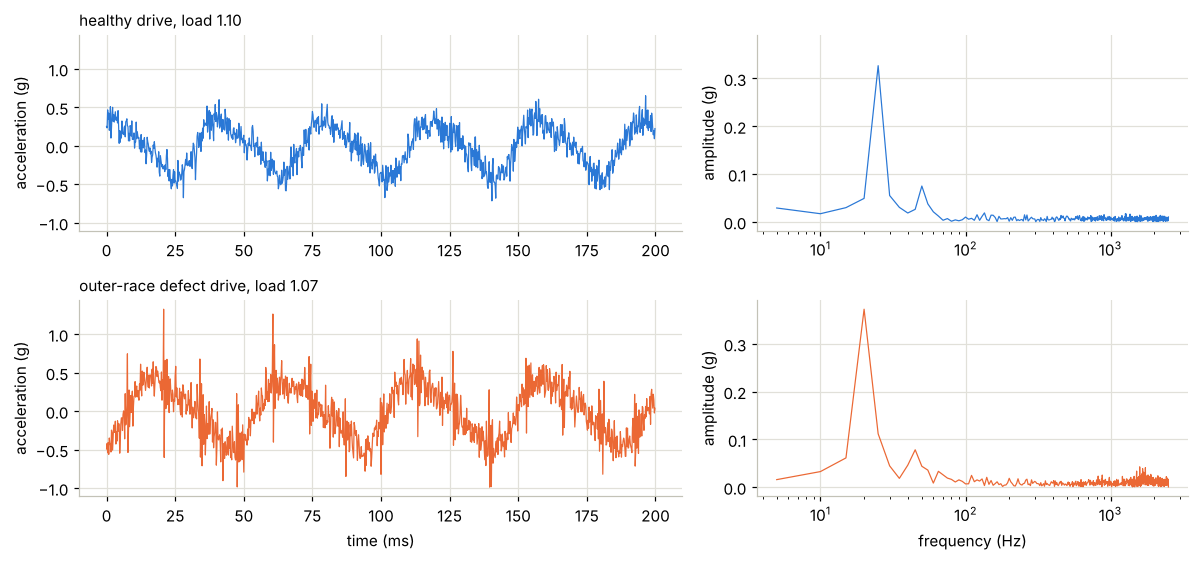

In [5]:
# Figure 1.1: one window from a healthy and a faulty drive at similar load
healthy_id = log[(log.label == 0)].sort_values("load").drive.iloc[-1]
faulty_id = log[(log.label == 1)].sort_values("load").drive.iloc[0]
fig, axes = plt.subplots(2, 2, figsize=(11, 5.2), gridspec_kw=dict(width_ratios=[1.4, 1]), sharey="col")
for row, (d, lab) in enumerate([(healthy_id, 0), (faulty_id, 1)]):
    x = log_raw[d][0]
    t = np.arange(WIN) / FS * 1000
    L = log[log.drive == d].load.iloc[0]
    axes[row, 0].plot(t, x, color=CLASS_COLORS[lab], lw=0.8)
    axes[row, 0].set_ylabel("acceleration (g)")
    axes[row, 0].set_title(f"{CLASS_NAMES[lab]} drive, load {L:.2f}", loc="left", fontsize=10)
    spec = np.abs(np.fft.rfft(x - x.mean())) * 2 / x.size
    fr = np.fft.rfftfreq(x.size, 1 / FS)
    axes[row, 1].semilogx(fr[1:], spec[1:], color=CLASS_COLORS[lab], lw=0.8)
    axes[row, 1].set_ylabel("amplitude (g)")
axes[1, 0].set_xlabel("time (ms)")
axes[1, 1].set_xlabel("frequency (Hz)")
fig.tight_layout()
savefig("ch01_signals")
plt.show()

The healthy window is a smooth sum of shaft-speed sines plus noise. The faulty one carries a burst
every few milliseconds, and the bursts put energy into the 1.5–2 kHz band where the healthy
spectrum is flat.

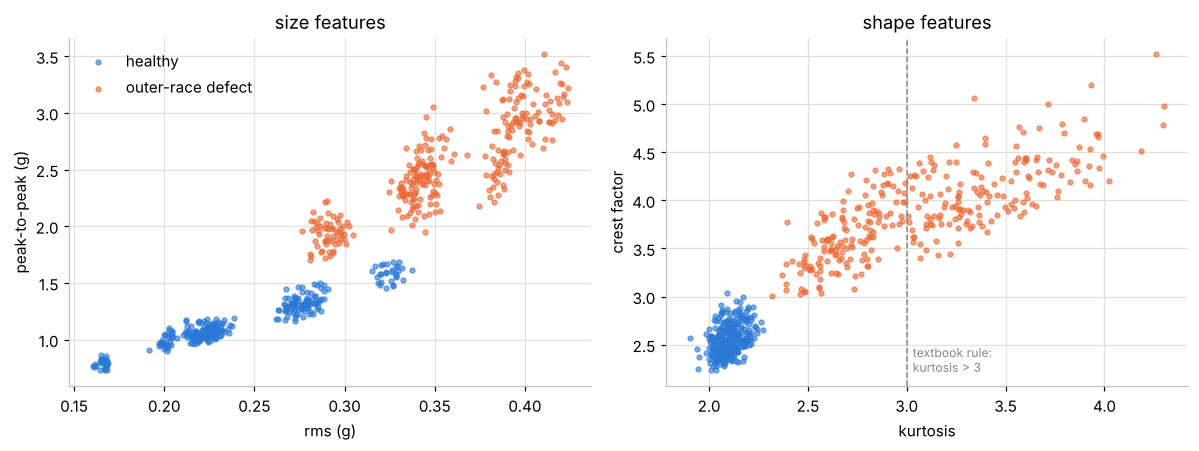

In [6]:
# Figure 1.2: the log in two feature planes
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for lab in (0, 1):
    s = log[log.label == lab]
    axes[0].scatter(s.rms, s["ptp"], s=10, alpha=0.6, color=CLASS_COLORS[lab], label=CLASS_NAMES[lab])
    axes[1].scatter(s["kurtosis"], s.crest, s=10, alpha=0.6, color=CLASS_COLORS[lab], label=CLASS_NAMES[lab])
axes[0].set(xlabel="rms (g)", ylabel="peak-to-peak (g)", title="size features")
axes[1].set(xlabel="kurtosis", ylabel="crest factor", title="shape features")
axes[1].axvline(3.0, color=MUTED, ls="--", lw=1)
axes[1].text(3.03, axes[1].get_ylim()[0] + 0.15, "textbook rule:\nkurtosis > 3", color=MUTED, fontsize=8)
axes[0].legend(loc="upper left")
fig.tight_layout()
savefig("ch01_feature_planes")
plt.show()

---
## 2. A rule written by hand

Gaussian random vibration has a kurtosis of 3; impacts make the distribution heavy-tailed and push
kurtosis up. A common hand rule in condition monitoring is therefore *alarm when kurtosis > 3*.

In [7]:
def report(name, y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    acc = (y_true == y_pred).mean()
    fa = y_pred[y_true == 0].mean()          # false-alarm rate on healthy windows
    miss = 1 - y_pred[y_true == 1].mean()    # miss rate on faulty windows
    print(f"{name:<34s} accuracy {acc:.3f}   false alarms {fa:.3f}   misses {miss:.3f}")
    return acc, fa, miss

report("hand rule: kurtosis > 3", log.label, (log["kurtosis"] > 3).astype(int))

# the same feature, threshold chosen from the data: midpoint between the classes
k_h_max = log["kurtosis"][log.label == 0].max()
k_f_min = log["kurtosis"][log.label == 1].min()
thr = 0.5 * (k_h_max + k_f_min)
print(f"healthy kurtosis max {k_h_max:.3f}, faulty kurtosis min {k_f_min:.3f} -> threshold {thr:.3f}")
report("data-set rule: kurtosis > %.2f" % thr, log.label, (log["kurtosis"] > thr).astype(int))

hand rule: kurtosis > 3            accuracy 0.760   false alarms 0.000   misses 0.480
healthy kurtosis max 2.274, faulty kurtosis min 2.316 -> threshold 2.295
data-set rule: kurtosis > 2.30     accuracy 1.000   false alarms 0.000   misses 0.000


(np.float64(1.0), np.float64(0.0), np.float64(0.0))

The physics picked the right feature; the textbook threshold is wrong for this machine, because the
strong shaft-speed sine pulls a healthy window's kurtosis well below 3 (a pure sine has 1.5). The
data move the threshold to where it belongs. That is machine learning in its smallest form.

---
## 3. The artificial neuron, from scratch

### 3.1 Perceptron

The neuron computes $z = \mathbf w^\top \mathbf x + b$ and outputs $\hat y = 1$ if $z \ge 0$,
else 0. Rosenblatt's learning rule visits the examples one at a time and nudges the weights only
when the prediction is wrong:

$$\mathbf w \leftarrow \mathbf w + \eta\,(y - \hat y)\,\mathbf x,\qquad b \leftarrow b + \eta\,(y-\hat y).$$

In [8]:
class Perceptron:
    """Rosenblatt perceptron for labels in {0, 1}."""

    def __init__(self, eta=0.1, n_epochs=30, seed=0):
        self.eta, self.n_epochs, self.seed = eta, n_epochs, seed

    def fit(self, X, y):
        rng = np.random.default_rng(self.seed)
        self.w_ = rng.normal(0, 0.01, X.shape[1])
        self.b_ = 0.0
        self.errors_ = []
        for _ in range(self.n_epochs):
            errors = 0
            for i in rng.permutation(len(y)):
                update = self.eta * (y[i] - self.predict(X[i]))
                self.w_ += update * X[i]
                self.b_ += update
                errors += int(update != 0.0)
            self.errors_.append(errors)
        return self

    def net_input(self, X):
        return X @ self.w_ + self.b_

    def predict(self, X):
        return (self.net_input(X) >= 0.0).astype(int)


def standardise(X, mu=None, sd=None):
    mu = X.mean(axis=0) if mu is None else mu
    sd = X.std(axis=0) if sd is None else sd
    return (X - mu) / sd, mu, sd


X_shape, mu_s, sd_s = standardise(log[SHAPE].to_numpy())
y_log = log.label.to_numpy()
ppn = Perceptron(eta=0.1, n_epochs=20).fit(X_shape, y_log)
print("updates per epoch:", ppn.errors_)
print("weights", ppn.w_.round(3), "bias", round(ppn.b_, 3))

updates per epoch: [5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
weights [0.113 0.121] bias 0.1


### 3.2 When the classes overlap

The perceptron rule only stops when every example is on the right side. Below, it is trained on
the size features from a second log (Section 5) in which load and condition are independent, so
the classes overlap. It never stops updating.

In [9]:
# a second campaign: 40 NEW drives, load independent of condition (used again in Section 6)
test, test_raw = campaign(40, load_healthy=(0.6, 2.2), load_faulty=(0.6, 2.2), seed=3, first_id=100)
X_size_test, _, _ = standardise(test[SIZE].to_numpy())
ppn_overlap = Perceptron(eta=0.1, n_epochs=20).fit(X_size_test, test.label.to_numpy())
print("updates per epoch:", ppn_overlap.errors_)

updates per epoch: [53, 26, 27, 17, 21, 12, 10, 13, 23, 11, 20, 15, 14, 14, 11, 12, 17, 13, 6, 12]


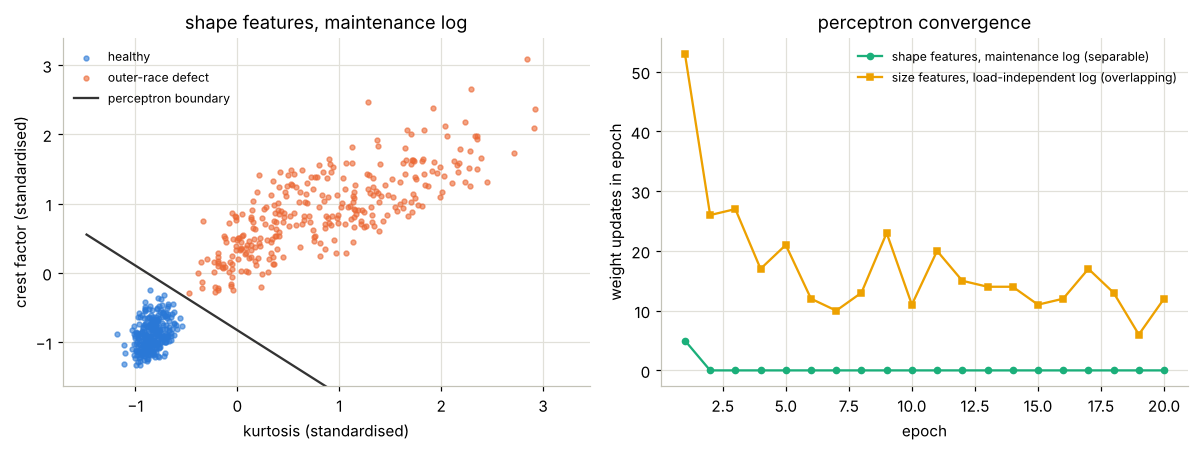

In [10]:
# Figure 1.3: perceptron boundary and updates per epoch
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
for lab in (0, 1):
    m = y_log == lab
    ax.scatter(X_shape[m, 0], X_shape[m, 1], s=10, alpha=0.6, color=CLASS_COLORS[lab], label=CLASS_NAMES[lab])
xx = np.linspace(X_shape[:, 0].min() - 0.3, X_shape[:, 0].max() + 0.3, 50)
ax.plot(xx, -(ppn.w_[0] * xx + ppn.b_) / ppn.w_[1], color="#333", lw=1.5, label="perceptron boundary")
ax.set_ylim(X_shape[:, 1].min() - 0.3, X_shape[:, 1].max() + 0.3)
ax.set(xlabel="kurtosis (standardised)", ylabel="crest factor (standardised)", title="shape features, maintenance log")
ax.legend(loc="upper left", fontsize=8)
ax = axes[1]
ep = np.arange(1, 21)
ax.plot(ep, ppn.errors_, "o-", color=AQUA, ms=4, label="shape features, maintenance log (separable)")
ax.plot(ep, ppn_overlap.errors_, "s-", color=YELLOW, ms=4, label="size features, load-independent log (overlapping)")
ax.set(xlabel="epoch", ylabel="weight updates in epoch", title="perceptron convergence")
ax.legend(fontsize=8)
fig.tight_layout()
savefig("ch01_perceptron")
plt.show()

### 3.3 Adaline: a loss and its gradient

Adaline keeps the same neuron but learns from the continuous output $z$ instead of the thresholded
one. It minimises the mean squared error

$$L(\mathbf w, b) = \frac1n\sum_{i=1}^n \bigl(y_i - z_i\bigr)^2,\qquad z_i = \mathbf w^\top\mathbf x_i + b,$$

by **gradient descent**, using the whole data set at every step:

$$\mathbf w \leftarrow \mathbf w + \eta\,\frac2n\sum_i (y_i - z_i)\,\mathbf x_i,\qquad
b \leftarrow b + \eta\,\frac2n\sum_i (y_i - z_i).$$

In [11]:
class Adaline:
    """Adaptive linear neuron trained by full-batch gradient descent on the MSE."""

    def __init__(self, eta=0.01, n_epochs=50, seed=0):
        self.eta, self.n_epochs, self.seed = eta, n_epochs, seed

    def fit(self, X, y):
        rng = np.random.default_rng(self.seed)
        self.w_ = rng.normal(0, 0.01, X.shape[1])
        self.b_ = 0.0
        self.losses_ = []
        for _ in range(self.n_epochs):
            err = y - self.net_input(X)
            self.w_ += self.eta * 2.0 * X.T @ err / len(y)
            self.b_ += self.eta * 2.0 * err.mean()
            self.losses_.append((err ** 2).mean())
        return self

    def net_input(self, X):
        return X @ self.w_ + self.b_

    def predict(self, X):
        return (self.net_input(X) >= 0.5).astype(int)


X_shape_raw = log[SHAPE].to_numpy()
runs = {
    "raw, eta = 0.1": Adaline(eta=0.1, n_epochs=50).fit(X_shape_raw, y_log),
    "raw, eta = 0.01": Adaline(eta=0.01, n_epochs=50).fit(X_shape_raw, y_log),
    "standardised, eta = 0.1": Adaline(eta=0.1, n_epochs=50).fit(X_shape, y_log),
    "standardised, eta = 0.5": Adaline(eta=0.5, n_epochs=50).fit(X_shape, y_log),
    "standardised, eta = 0.55": Adaline(eta=0.55, n_epochs=50).fit(X_shape, y_log),
}
# gradient descent on a quadratic loss is stable only for eta < 2 / (largest eigenvalue of its Hessian)
for name, X in [("raw", X_shape_raw), ("standardised", X_shape)]:
    A = np.c_[X, np.ones(len(X))]
    ev = np.linalg.eigvalsh(2 * A.T @ A / len(X))
    print(f"{name:<13s} Hessian eigenvalues {np.round(ev, 3)}  -> stable for eta < {2 / ev.max():.3f}")
for k, a in runs.items():
    l = np.array(a.losses_)
    acc = (a.predict(X_shape if k.startswith("standardised") else X_shape_raw) == y_log).mean() if np.isfinite(l[-1]) else float("nan")
    print(f"{k:<26s} loss after 1 epoch {l[0]:10.3g}   after 50 epochs {l[-1]:10.3g}   accuracy {acc:.3f}")

raw           Hessian eigenvalues [ 0.057  0.093 37.876]  -> stable for eta < 0.053
standardised  Hessian eigenvalues [0.138 2.    3.862]  -> stable for eta < 0.518
raw, eta = 0.1             loss after 1 epoch      0.501   after 50 epochs   1.46e+43   accuracy 0.500
raw, eta = 0.01            loss after 1 epoch      0.501   after 50 epochs      0.152   accuracy 0.997
standardised, eta = 0.1    loss after 1 epoch        0.5   after 50 epochs     0.0503   accuracy 0.975
standardised, eta = 0.5    loss after 1 epoch        0.5   after 50 epochs     0.0489   accuracy 0.977
standardised, eta = 0.55   loss after 1 epoch        0.5   after 50 epochs   1.87e+04   accuracy 0.040


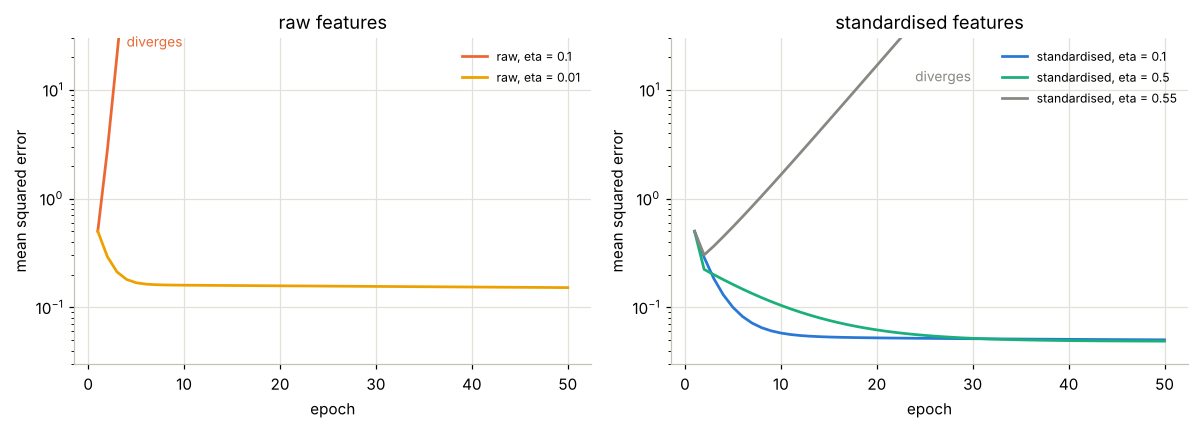

In [12]:
# Figure 1.4: Adaline loss curves
fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
ep = np.arange(1, 51)
styles = {"raw, eta = 0.1": ORANGE, "raw, eta = 0.01": YELLOW}
for k, c in styles.items():
    axes[0].semilogy(ep, runs[k].losses_, color=c, lw=1.8, label=k)
axes[0].set(xlabel="epoch", ylabel="mean squared error", title="raw features")
axes[0].legend(fontsize=8)
for k, c in [("standardised, eta = 0.1", BLUE), ("standardised, eta = 0.5", AQUA), ("standardised, eta = 0.55", MUTED)]:
    axes[1].semilogy(ep, runs[k].losses_, color=c, lw=1.8, label=k)
axes[1].set(xlabel="epoch", ylabel="mean squared error", title="standardised features")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_ylim(0.03, 30)          # the diverging runs leave the plot; the printed losses give their size
axes[0].annotate("diverges", xy=(4, 25), color=ORANGE, fontsize=9)
axes[1].annotate("diverges", xy=(24, 12), color=MUTED, fontsize=9)
fig.tight_layout()
savefig("ch01_adaline")
plt.show()

---
## 4. The same thing in scikit-learn

Every classical model in Chapters 2 to 7 follows the pattern below: split, `fit` on the training
part, `predict` / `score` on the part the model has not seen. A `Pipeline` keeps the scaler's
statistics on the training side.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Perceptron as SkPerceptron
from sklearn.metrics import confusion_matrix

X_train, X_val, y_train, y_val = train_test_split(
    log[FEATURES], log.label, test_size=0.3, random_state=0, stratify=log.label)
print("train", X_train.shape, " validation", X_val.shape)

models = {}
for name, cols in [("lab-4 features", LAB4), ("size features", SIZE), ("shape features", SHAPE)]:
    clf = make_pipeline(StandardScaler(), LogisticRegression())
    clf.fit(X_train[cols], y_train)
    models[name] = (clf, cols)
    y_hat = clf.predict(X_val[cols])
    report(f"logistic regression, {name}", y_val, y_hat)

sk_ppn = make_pipeline(StandardScaler(), SkPerceptron(random_state=0)).fit(X_train[SHAPE], y_train)
report("sklearn Perceptron, shape features", y_val, sk_ppn.predict(X_val[SHAPE]))
print("confusion matrix, lab-4 model:\n", confusion_matrix(y_val, models["lab-4 features"][0].predict(X_val[LAB4])))

train (420, 6)  validation (180, 6)
logistic regression, lab-4 features accuracy 0.994   false alarms 0.000   misses 0.011
logistic regression, size features accuracy 1.000   false alarms 0.000   misses 0.000
logistic regression, shape features accuracy 0.994   false alarms 0.000   misses 0.011
sklearn Perceptron, shape features accuracy 1.000   false alarms 0.000   misses 0.000
confusion matrix, lab-4 model:
 [[90  0]
 [ 1 89]]


Every feature set scores 99 % or better on the held-out windows. By this test there is nothing to
choose between them.

---
## 5. The decisive experiment: fault or load?

The validation set in Section 4 came from the same log as the training set, so it carries the same
coincidence: faulty drives ran harder. A model can score 99 % by recognising *load*. The test
below uses the second campaign from Section 3.2: **40 new drives** whose load (0.6–2.2 of rated)
is independent of their condition. All models are the ones trained in Section 4; nothing is
refitted.

In [14]:
results = []
for name, (clf, cols) in models.items():
    acc, fa, miss = report(f"{name} on new drives", test.label, clf.predict(test[cols]))
    results.append((name, acc, fa, miss))
acc, fa, miss = report("data-set rule kurtosis > %.2f" % thr, test.label, (test["kurtosis"] > thr).astype(int))
results.append(("kurtosis rule", acc, fa, miss))

bins = [0.6, 1.0, 1.4, 1.8, 2.21]
test["load_bin"] = pd.cut(test.load, bins, right=False)
table = []
for name, (clf, cols) in models.items():
    p = clf.predict(test[cols])
    for b, g in test.assign(p=p).groupby("load_bin", observed=True):
        table.append((name, str(b), g.p[g.label == 0].mean(), 1 - g.p[g.label == 1].mean()))
by_load = pd.DataFrame(table, columns=["model", "load", "false_alarm", "miss"])
print(by_load.pivot(index="load", columns="model", values=["false_alarm", "miss"]).round(2))

lab-4 features on new drives       accuracy 0.618   false alarms 0.495   misses 0.268
size features on new drives        accuracy 0.632   false alarms 0.457   misses 0.278
shape features on new drives       accuracy 0.993   false alarms 0.003   misses 0.010
data-set rule kurtosis > 2.30      accuracy 0.998   false alarms 0.003   misses 0.002
               false_alarm                                        miss  \
model       lab-4 features shape features size features lab-4 features   
load                                                                     
[0.6, 1.0)            0.00           0.00          0.00           0.74   
[1.0, 1.4)            0.34           0.01          0.23           0.23   
[1.4, 1.8)            0.92           0.00          0.88           0.00   
[1.8, 2.21)           1.00           0.01          1.00           0.00   

                                          
model       shape features size features  
load                                      
[0.6, 1.

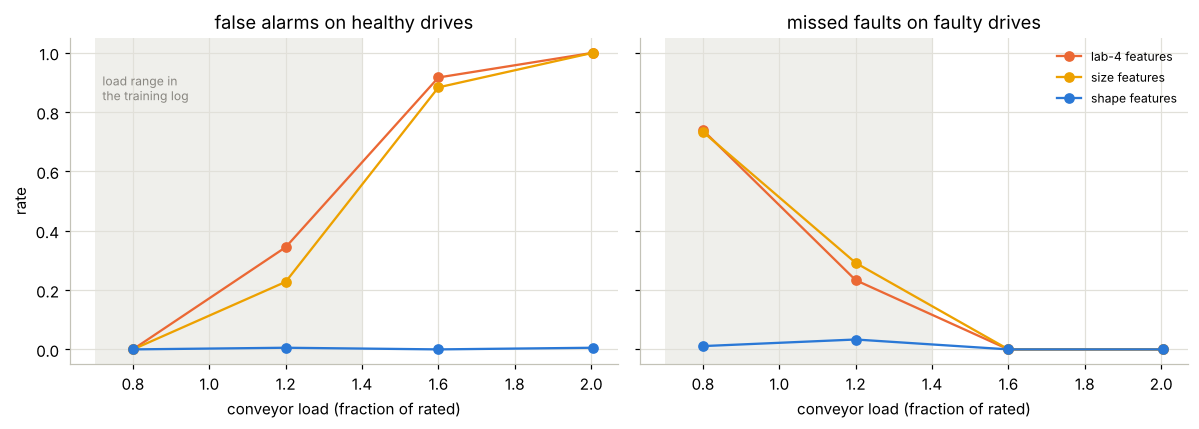

In [15]:
# Figure 1.5: false-alarm and miss rates against load
fig, axes = plt.subplots(1, 2, figsize=(11, 4.0), sharey=True)
centres = 0.5 * (np.array(bins[:-1]) + np.array(bins[1:]))
colors = {"lab-4 features": ORANGE, "size features": YELLOW, "shape features": BLUE}
for name, c in colors.items():
    s = by_load[by_load.model == name]
    axes[0].plot(centres, s.false_alarm, "o-", color=c, label=name)
    axes[1].plot(centres, s.miss, "o-", color=c, label=name)
for ax, ttl in zip(axes, ["false alarms on healthy drives", "missed faults on faulty drives"]):
    ax.axvspan(0.7, 1.4, color="#e1e0d9", alpha=0.5, lw=0)
    ax.set(xlabel="conveyor load (fraction of rated)", title=ttl)
axes[0].text(0.72, 0.93, "load range in\nthe training log", fontsize=8, color=MUTED, va="top")
axes[0].set_ylabel("rate")
axes[1].legend(fontsize=8)
fig.tight_layout()
savefig("ch01_decisive")
plt.show()

In [16]:
coef = pd.DataFrame({name: pd.Series(clf[-1].coef_[0], index=cols) for name, (clf, cols) in models.items()})
print("logistic-regression weights on standardised features:\n", coef.round(2))
print("\ncorrelation of each feature with load in the training log:")
print(log[FEATURES + ["load"]].corr()["load"].drop("load").round(2))
print("\n... and within each class:")
print(pd.DataFrame({CLASS_NAMES[c]: g[FEATURES + ["load"]].corr()["load"].drop("load") for c, g in log.groupby("label")}).round(2))

logistic-regression weights on standardised features:
           lab-4 features  size features  shape features
crest                NaN            NaN            3.67
kurtosis             NaN            NaN            3.44
mean               -1.01            NaN             NaN
ptp                 5.17           5.66             NaN
rms                 0.39          -0.11             NaN
std                 0.41            NaN             NaN

correlation of each feature with load in the training log:
mean       -0.30
std         0.81
rms         0.81
ptp         0.80
kurtosis    0.71
crest       0.74
Name: load, dtype: float64

... and within each class:
          healthy  outer-race defect
mean        -0.07              -0.14
std          0.75               0.06
rms          0.75               0.06
ptp          0.71              -0.00
kurtosis     0.04               0.08
crest        0.02              -0.01


The models built on size features learned *load*: they raise an alarm on every healthy drive
pushed past 1.4 of rated, and they sleep through faults on lightly loaded conveyors. The shape
features are dimensionless, so a change of load cancels out of them, and the shape model holds
on drives and loads it never saw.

---
## Exercises (starter cells)

1. Remove the confound: regenerate the maintenance log with both classes at load 0.7–1.4 and
   repeat Sections 4 and 6. Does the lab-4 model still fail?
2. Train the from-scratch `Adaline` on `["rms", "ptp", "kurtosis", "crest"]`. Inspect the weights.
3. Lower the defect severity to 0.2–0.4 and find where the shape model starts missing faults.

In [17]:
# Exercise 1 starter
# log2, _ = campaign(20, load_healthy=(0.7, 1.4), load_faulty=(0.7, 1.4), seed=1, first_id=0)